# Working with a Sentinel-2 products in Python using OPeNDAP and xarray

This tutorial shows how to access a single Copernicus Sentinel-2 L2A product hosted on our THREDDS server at [nbstds.met.no](https://nbstds.met.no/thredds/catalog/NBS/catalog.html), without downloading the whole file.

You will learn how to:
1. Open the product remotely through OPeNDAP using `xarray`
2. Inspect a single variable and its metadata
3. Inspect the global attributes
4. Select only a few variables
5. Read only a spatial subset (X/Y range), taking the chunking of the file into account
6. Plot a true-colour image

The libraries needed can be installed with `pip install xarray netCDF4 numpy matplotlib`.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

/home/lukem/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. What is OPeNDAP and how do we open the data?

[OPeNDAP](https://www.opendap.org/) (Open-source Project for a Network Data Access Protocol) is a protocol that lets a client request all or part of a remote dataset over HTTP. The server (here THREDDS) exposes the file as a set of variables and dimensions, and the client only downloads the values it actually asks for. This is very useful for Sentinel-2, where a single product covers 110 x 110 km and contains many large bands.

Each product on the THREDDS server has an OPeNDAP URL. The URL used below is the one shown in the browser (`...nc.html`) without the `.html` suffix. 

`xarray.open_dataset` accepts such a URL directly. Opening is *lazy*: only metadata and the small coordinate variables are read, while the band arrays are not loaded until we need their values.

> **Note**: Products are only kept in the netCDF archive for a limited time (rolling archive). If the URL below no longer works, browse the [catalog](https://nbstds.met.no/thredds/catalog/NBS/catalog.html) and replace it with the OPeNDAP URL of another Sentinel-2 L2A product.

In [2]:
url = (
    "https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/"
    "S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc"
)

ds = xr.open_dataset(url)
ds

<xarray.Dataset> Size: 8GB
Dimensions:         (raster_band_id: 13, time: 1, ya: 22, xa: 22, orbit_dim: 3,
                     y: 10980, x: 10980)
Coordinates:
  * time            (time) datetime64[ns] 8B 2026-11-24T10:43:01
  * y               (y) int32 44kB 6900000 6899990 6899980 ... 6790220 6790210
  * x               (x) int32 44kB 600000 600010 600020 ... 709770 709780 709790
Dimensions without coordinates: raster_band_id, ya, xa, orbit_dim
Data variables: (12/25)
    band_id         (raster_band_id) int32 52B ...
    UTM_projection  int32 4B ...
    view_azimuth    (time, raster_band_id, ya, xa) float32 25kB ...
    view_zenith     (time, raster_band_id, ya, xa) float32 25kB ...
    sun_zenith      (time, ya, xa) float32 2kB ...
    sun_azimuth     (time, ya, xa) float32 2kB ...
    ...              ...
    B9              (time, y, x) float32 482MB ...
    MSK_CLDPRB      (time, y, x) float32 482MB ...
    MSK_SNWPRB      (time, y, x) float32 482MB ...
    AOT             (time, y, x) float32 482MB ...
    WVP             (time, y, x) float32 482MB ...
    SCL             (time, y, x) float32 482MB ...
Attributes: (12/111)
    institution:                           Norwegian Meteorological Institute...
    creator_role:                          Data center contact
    creator_name:                          NBS Helpdesk
    creator_email:                         nbs-helpdesk@met.no
    creator_url:                           https://met.no
    creator_institution:                   Norwegian Meteorological Institute
    ...                                    ...
    id:                                    7720eb14-1d67-48a8-a7c4-c9376b71767b
    date_metadata_modified:                2026-11-24T16:47:59.830898Z
    date_metadata_modified_type:           Created
    date_created:                          2026-11-24T16:47:59.830898Z
    history:                               2026-11-24T16:47:59.830898Z: Conve...
    DODS_EXTRA.Unlimited_Dimension:        time

The output shows the structure of the product:

- **Dimensions**: `time` (always 1 for a single product), and `y` / `x` (10980 x 10980 pixels at 10 m resolution).
- **Coordinates**: `time`, `x` and `y`. `x` and `y` are projected coordinates in metres in the UTM zone of the tile (here UTM zone 32N, EPSG:32632).
- **Data variables**: the spectral bands `B1`-`B12`, masks and quality layers (`MSK_CLDPRB`, `MSK_SNWPRB`, `SCL`, `AOT`, `WVP`), viewing/sun angles, and `UTM_projection` which describes the coordinate reference system.

All bands are provided on the same 10 m grid, which means that the 20 m and 60 m bands of the original product have been resampled.

## 2. Viewing a single variable and its metadata

A variable is accessed like a dictionary key. We take the red band `B4` as an example. This does not download the data; it only gives us a lazily loaded `DataArray`.

In [3]:
ds["B4"]

<xarray.DataArray 'B4' (time: 1, y: 10980, x: 10980)> Size: 482MB
[120560400 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8B 2026-11-24T10:43:01
  * y        (y) int32 44kB 6900000 6899990 6899980 ... 6790230 6790220 6790210
  * x        (x) int32 44kB 600000 600010 600020 600030 ... 709770 709780 709790
Attributes:
    standard_name:          surface_bidirectional_reflectance
    long_name:              Reflectance in band B4
    bandwidth:              30
    bandwidth_unit:         nm
    wavelength:             665
    wavelength_unit:        nm
    solar_irradiance:       1512.06
    solar_irradiance_unit:  W/m2/um
    units:                  1
    grid_mapping:           UTM_projection

In [4]:
for key, value in ds["B4"].attrs.items():
    print(f"{key:>20}: {value}")

       standard_name: surface_bidirectional_reflectance
           long_name: Reflectance in band B4
           bandwidth: 30
      bandwidth_unit: nm
          wavelength: 665
     wavelength_unit: nm
    solar_irradiance: 1512.06
solar_irradiance_unit: W/m2/um
               units: 1
        grid_mapping: UTM_projection


The metadata follows the [CF conventions](https://cfconventions.org/) and describes how to interpret the numbers:

| Attribute | Meaning |
|---|---|
| `standard_name` | A name from the [CF Standard Name Table](https://cfconventions.org/Data/cf-standard-names/current/build/cf-standard-name-table.html), which gives the variable an unambiguous, machine-readable definition. Here `surface_bidirectional_reflectance`. |
| `long_name` | A free-text, human-readable description ("Reflectance in band B4"). |
| `units` | Physical unit. `1` means dimensionless, which is the case for reflectance. |
| `wavelength`, `bandwidth` (+ `_unit`) | Central wavelength and width of the spectral band, here 665 nm and 30 nm. |
| `solar_irradiance` (+ `_unit`) | Mean solar irradiance in the band. |
| `grid_mapping` | Name of the variable (`UTM_projection`) that describes the coordinate reference system. |

The reflectance is stored as an integer. To get the reflectance as a a physical value it must be divided by the quantification value, which is given as a global attribute (see next section).

## 3. Viewing the global attributes

Global attributes describe the product as a whole. They are available in `ds.attrs`.

In [5]:
for key, value in ds.attrs.items():
    print(f"{key:>40}: {value}")

                             institution: Norwegian Meteorological Institute (METNO)
                            creator_role: Data center contact
                            creator_name: NBS Helpdesk
                           creator_email: nbs-helpdesk@met.no
                             creator_url: https://met.no
                     creator_institution: Norwegian Meteorological Institute
                        contributor_role: Metadata author
                        contributor_name: NBS Helpdesk
                       contributor_email: nbs-helpdesk@met.no
                         contributor_url: https://met.no
                 contributor_institution: Norwegian Meteorological Institute
                          publisher_name: NBS Helpdesk
                         publisher_email: nbs-helpdesk@met.no
                  publisher_organisation: Norwegian Meteorological Institute
                           publisher_url: https://met.no
                         metadata_status: 

The global attributes can be grouped as follows:

- **Discovery and provenance** (`title`, `summary`, `id`, `keywords`, `project`, `institution`, `creator_*`, `publisher_*`, `history`, `date_created`): who produced the file and how. These follow the [Attribute Convention for Data Discovery (ACDD)](https://wiki.esipfed.org/Attribute_Convention_for_Data_Discovery_1-3), and `Conventions` states which standards are used (CF and ACDD).
- **License** (`license`, `license_text`, `access_constraint`): the Copernicus Sentinel data legal notice.
- **Platform and instrument** (`platform`, `instrument`, and their `_vocabulary` links): Sentinel-2A and its Multi-Spectral Imager (MSI).
- **Time and space coverage** (`time_coverage_start`, `time_coverage_end`, `geospatial_lat_min/max`, `geospatial_lon_min/max`): when and where the data was acquired.
- **Orbit** (`orbit_number`, `relative_orbit_number`, `orbit_direction`).
- **Product information inherited from the original SAFE product** (`PRODUCT_URI`, `PRODUCT_TYPE`, `PROCESSING_BASELINE`, `PRODUCT_DOI`, `GENERATION_TIME`, quality flags such as `GENERAL_QUALITY`).
- **Scene statistics** (`cloud_coverage`, `*_PERCENTAGE` for vegetation, water, snow/ice, cloud shadow, etc.).
- **Quantification values** (`BOA_QUANTIFICATION_VALUE`, `AOT_QUANTIFICATION_VALUE`, `WVP_QUANTIFICATION_VALUE`): factors that convert the stored integers to physical values.

Since the attributes are read when the file is opened, they can be used to quickly check a product (e.g. cloud cover) without loading any band data.

In [6]:
print("Title:            ", ds.attrs["title"])
print("Acquisition time: ", ds.attrs["time_coverage_start"])
print("Cloud cover [%]:  ", ds.attrs["cloud_coverage"])
print("Snow/ice [%]:     ", ds.attrs["SNOW_ICE_PERCENTAGE"])
print("BOA quantification value:", ds.attrs["BOA_QUANTIFICATION_VALUE"])

Title:             S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508
Acquisition time:  2026-11-24T10:43:01.024Z
Cloud cover [%]:   3.923342
Snow/ice [%]:      54.001343
BOA quantification value: 10000


## 4. Opening only a few variables

It is often convenient to work with only the variables you need. For a true-colour image we need the red (`B4`), green (`B3`) and blue (`B2`) bands. We also keep `UTM_projection`, which describes the coordinate reference system.

Selecting with a list of names returns a new, smaller `Dataset`.

The `Data URL` on the GUI of the data access form can also be updated by selecting the checkboxes of the desired variables.
https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc.html

In [7]:
rgb_vars = ["B4", "B3", "B2"]

# Amend the OPeNDAP URL with a constraint expression listing the variables we want
url_vars = f"{url}?{','.join(rgb_vars + ['UTM_projection'])}"
print(url_vars)

ds_rgb = xr.open_dataset(url_vars)
ds_rgb

https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc?B4,B3,B2,UTM_projection


<xarray.Dataset> Size: 1GB
Dimensions:         (time: 1, y: 10980, x: 10980)
Dimensions without coordinates: time, y, x
Data variables:
    UTM_projection  int32 4B ...
    B4              (time, y, x) float32 482MB ...
    B3              (time, y, x) float32 482MB ...
    B2              (time, y, x) float32 482MB ...
Attributes: (12/111)
    institution:                           Norwegian Meteorological Institute...
    creator_role:                          Data center contact
    creator_name:                          NBS Helpdesk
    creator_email:                         nbs-helpdesk@met.no
    creator_url:                           https://met.no
    creator_institution:                   Norwegian Meteorological Institute
    ...                                    ...
    id:                                    7720eb14-1d67-48a8-a7c4-c9376b71767b
    date_metadata_modified:                2026-11-24T16:47:59.830898Z
    date_metadata_modified_type:           Created
    date_created:                          2026-11-24T16:47:59.830898Z
    history:                               2026-11-24T16:47:59.830898Z: Conve...
    DODS_EXTRA.Unlimited_Dimension:        time

The dataset now only contains the requested variables. The global attributes and variable metadata are still available, since they are served together with the data:

In [8]:
print("Variables:", list(ds_rgb.data_vars))
print("Title:    ", ds_rgb.attrs["title"])
print("B4 long_name:", ds_rgb["B4"].attrs["long_name"])

Variables: ['UTM_projection', 'B4', 'B3', 'B2']
Title:     S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508
B4 long_name: Reflectance in band B4


## 5. Opening only a part of the data (X and Y range)

### How the data are chunked

The netCDF files on the NBS THREDDS server are created with the [`safe_to_netcdf`](https://github.com/NasjonaltBakkeSegment/safe_to_netcdf) tool. The bands are stored in **chunks** of `(time, y, x) = (1, 2745, 2745)` pixels. A chunk is the smallest unit that is read and decompressed from the file. Since 10980 = 4 x 2745, each band consists of 4 x 4 = 16 chunks.

This has some consequences for how you should request data:
- If you ask for a small area, the server only needs to read and decompress the chunks that overlap that area, not the whole band.
- All chunks intersected by the request will be loaded before subsetting. Aligning requests to the chunk grid is the most efficient, but it is not required.

The way a variable is stored in the file can be inspected through its `encoding`.

In [9]:
# Information about how the variable is stored
print(ds["B4"].encoding)

{'dtype': dtype('int16'), 'source': 'https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc', 'original_shape': (1, 10980, 10980), '_FillValue': 0, '_Unsigned': 'true'}


We use the known chunk size defined above to compute the chunk layout. This is used in the next section to check how many chunks a request touches:

In [10]:
# Chunk layout of the NBS Sentinel-2 netCDF files
chunk_size = 2745
n_chunks_y = ds.sizes["y"] // chunk_size
n_chunks_x = ds.sizes["x"] // chunk_size

print(f"Chunk size (y, x): ({chunk_size}, {chunk_size}) pixels = {chunk_size * 10 / 1000:.1f} km x {chunk_size * 10 / 1000:.1f} km")
print(f"Chunks per band: {n_chunks_y} x {n_chunks_x} = {n_chunks_y * n_chunks_x}")
print(f"Full band size: {ds['B4'].size * 2 / 1e6:.0f} MB (uint16)")

Chunk size (y, x): (2745, 2745) pixels = 27.4 km x 27.4 km
Chunks per band: 4 x 4 = 16
Full band size: 241 MB (uint16)


### Selecting by X and Y range

The coordinates `x` and `y` are projected coordinates in metres (UTM zone 32N), with `x` increasing from west to east and **`y` decreasing from north to south**. Let us look at the extent of the tile, using the product we opened in section 1:

In [11]:
print(f"x: {ds.x.values[0]} to {ds.x.values[-1]} m (step {ds.x.values[1] - ds.x.values[0]} m)")
print(f"y: {ds.y.values[0]} to {ds.y.values[-1]} m (step {ds.y.values[1] - ds.y.values[0]} m)")

x: 600000 to 709790 m (step 10 m)
y: 6900000 to 6790210 m (step -10 m)


A subset can also be requested through the OPeNDAP URL. For each variable, a constraint expression gives the **index range** to return for every dimension, using the syntax

```
<variable>[start:stride:stop][start:stride:stop]...
```

with one bracket per dimension in the order of the variable (here `time`, `y`, `x`), zero-based indices, and an **inclusive** `stop`. For example, `B4[0:1:0][100:1:199][300:1:399]` returns 100 rows and 100 columns of band `B4`.

The server only knows about indices, so we first convert our `x` and `y` range in metres to index ranges, using the coordinates read from the full product. We choose a 20 km x 20 km area in the middle of the tile. Since `y` is decreasing, the range goes from the larger to the smaller value. We also check which chunks of the file this area overlaps.

In [12]:
x_min, x_max = 640_000, 660_000
y_max, y_min = 6_850_000, 6_830_000  # y is decreasing: start with the largest value

# Convert the coordinate range (metres) to index ranges
xi = ds.get_index("x").slice_indexer(x_min, x_max)
yi = ds.get_index("y").slice_indexer(y_max, y_min)
x_start, x_stop = xi.start, xi.stop - 1  # OPeNDAP stop index is inclusive
y_start, y_stop = yi.start, yi.stop - 1
print(f"x indices: {x_start}-{x_stop}, y indices: {y_start}-{y_stop}")

# Which chunks of the file does this area overlap?
chunks_x = range(x_start // chunk_size, x_stop // chunk_size + 1)
chunks_y = range(y_start // chunk_size, y_stop // chunk_size + 1)
n_pixels = (x_stop - x_start + 1) * (y_stop - y_start + 1)
print(f"Chunks touched per band: {len(chunks_y) * len(chunks_x)} of {n_chunks_y * n_chunks_x}")

# Amend the OPeNDAP URL with the variables AND the index ranges: [time][y][x]
index_range = f"[0:1:0][{y_start}:1:{y_stop}][{x_start}:1:{x_stop}]"
constraint = ",".join(f"{var}{index_range}" for var in rgb_vars) + ",UTM_projection"
url_subset = f"{url}?{constraint}"
print(url_subset)

# Open the product again, from scratch, now with the subset URL
ds_sub = xr.open_dataset(url_subset)
ds_sub

x indices: 4000-6000, y indices: 5000-7000
Chunks touched per band: 4 of 16
https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc?B4[0:1:0][5000:1:7000][4000:1:6000],B3[0:1:0][5000:1:7000][4000:1:6000],B2[0:1:0][5000:1:7000][4000:1:6000],UTM_projection


<xarray.Dataset> Size: 48MB
Dimensions:         (time: 1, y: 2001, x: 2001)
Dimensions without coordinates: time, y, x
Data variables:
    UTM_projection  int32 4B ...
    B4              (time, y, x) float32 16MB ...
    B3              (time, y, x) float32 16MB ...
    B2              (time, y, x) float32 16MB ...
Attributes: (12/111)
    institution:                           Norwegian Meteorological Institute...
    creator_role:                          Data center contact
    creator_name:                          NBS Helpdesk
    creator_email:                         nbs-helpdesk@met.no
    creator_url:                           https://met.no
    creator_institution:                   Norwegian Meteorological Institute
    ...                                    ...
    id:                                    7720eb14-1d67-48a8-a7c4-c9376b71767b
    date_metadata_modified:                2026-11-24T16:47:59.830898Z
    date_metadata_modified_type:           Created
    date_created:                          2026-11-24T16:47:59.830898Z
    history:                               2026-11-24T16:47:59.830898Z: Conve...
    DODS_EXTRA.Unlimited_Dimension:        time

The dataset we opened only has the selected area, and its `x` and `y` coordinates are already restricted to the requested range. The band values are still not transferred. We load them into memory with `.load()`; this is the step where only the selected area of the selected bands is downloaded.

> **Note**: If opening a URL with a constraint expression fails, make sure your `netCDF4` library has OPeNDAP support, or try the `pydap` engine: `xr.open_dataset(url_subset, engine="pydap")`.

In [13]:
t0 = time.time()
ds_sub = ds_sub.load()
print(f"Loaded in {time.time() - t0:.1f} s")
ds_sub

Loaded in 6.1 s


<xarray.Dataset> Size: 48MB
Dimensions:         (time: 1, y: 2001, x: 2001)
Dimensions without coordinates: time, y, x
Data variables:
    UTM_projection  int32 4B -2147483647
    B4              (time, y, x) float32 16MB 2.45e+03 2.285e+03 ... 1.826e+03
    B3              (time, y, x) float32 16MB 2.622e+03 2.33e+03 ... 2.38e+03
    B2              (time, y, x) float32 16MB 3.003e+03 2.817e+03 ... 3.107e+03
Attributes: (12/111)
    institution:                           Norwegian Meteorological Institute...
    creator_role:                          Data center contact
    creator_name:                          NBS Helpdesk
    creator_email:                         nbs-helpdesk@met.no
    creator_url:                           https://met.no
    creator_institution:                   Norwegian Meteorological Institute
    ...                                    ...
    id:                                    7720eb14-1d67-48a8-a7c4-c9376b71767b
    date_metadata_modified:                2026-11-24T16:47:59.830898Z
    date_metadata_modified_type:           Created
    date_created:                          2026-11-24T16:47:59.830898Z
    history:                               2026-11-24T16:47:59.830898Z: Conve...
    DODS_EXTRA.Unlimited_Dimension:        time

## 6. Plotting a true-colour image

The plots show the **whole product**, not the subset from section 5, so we start by opening the product again through OPeNDAP. A true-colour (RGB) image combines the red (B4), green (B3) and blue (B2) bands. The steps are:

1. Open the whole product through OPeNDAP, reading only every n-th pixel to keep the transfer manageable.
2. Stack the three bands into an array with shape `(y, x, 3)` and convert the stored integers to reflectance.
3. Compute the extent of the image in UTM coordinates, so the axes show real coordinates.
4. Stretch the values to the range 0-1 that `imshow` expects. We first do this using the full range of the data, and then with a percentile clip to improve the contrast.

### 6.1 Open the whole product

A full band is 10980 x 10980 pixels (241 MB as uint16) and we need three of them, about 720 MB. A screen cannot show that many pixels anyway, so we use the `stride` in the constraint expression from section 5 to read only every 5th pixel in both directions. This still covers the whole tile, but as 2196 x 2196 pixels at 50 m resolution, which is 25 times less data. Set `stride = 1` to get the full 10 m resolution, at the cost of a longer download and more memory.

In [14]:
stride = 5  # read every 5th pixel; use 1 for the full 10 m resolution

# Index range covering the whole tile: [time][y][x]
index_range = f"[0:1:0][0:{stride}:{ds.sizes['y'] - 1}][0:{stride}:{ds.sizes['x'] - 1}]"
constraint = ",".join(f"{var}{index_range}" for var in rgb_vars) + ",UTM_projection"
url_full = f"{url}?{constraint}"
print(url_full)

# Open the product again, from scratch, and load the values
ds_full = xr.open_dataset(url_full)
t0 = time.time()
ds_full = ds_full.load()
print(f"Loaded in {time.time() - t0:.1f} s")
print(f"Size: {ds_full.sizes['y']} x {ds_full.sizes['x']} pixels")
ds_full

https://nbstds.met.no/thredds/dodsC/NBS/S2A/2026/11/24/S2A_MSIL2A_20261124T104301_N0513_R008_T32VPP_20261124T152508.nc?B4[0:1:0][0:5:10979][0:5:10979],B3[0:1:0][0:5:10979][0:5:10979],B2[0:1:0][0:5:10979][0:5:10979],UTM_projection
Loaded in 12.4 s
Size: 2196 x 2196 pixels


<xarray.Dataset> Size: 58MB
Dimensions:         (time: 1, y: 2196, x: 2196)
Dimensions without coordinates: time, y, x
Data variables:
    UTM_projection  int32 4B -2147483647
    B4              (time, y, x) float32 19MB 8.72e+03 8.853e+03 ... 3.091e+03
    B3              (time, y, x) float32 19MB 7.498e+03 7.734e+03 ... 3.242e+03
    B2              (time, y, x) float32 19MB 8.05e+03 8.114e+03 ... 3.815e+03
Attributes: (12/111)
    institution:                           Norwegian Meteorological Institute...
    creator_role:                          Data center contact
    creator_name:                          NBS Helpdesk
    creator_email:                         nbs-helpdesk@met.no
    creator_url:                           https://met.no
    creator_institution:                   Norwegian Meteorological Institute
    ...                                    ...
    id:                                    7720eb14-1d67-48a8-a7c4-c9376b71767b
    date_metadata_modified:                2026-11-24T16:47:59.830898Z
    date_metadata_modified_type:           Created
    date_created:                          2026-11-24T16:47:59.830898Z
    history:                               2026-11-24T16:47:59.830898Z: Conve...
    DODS_EXTRA.Unlimited_Dimension:        time

### 6.2 Stack the bands and convert to reflectance

`np.dstack` puts the red, green and blue bands on top of each other in the order `imshow` expects. The stored integers are converted to reflectance by dividing by `BOA_QUANTIFICATION_VALUE`, and no-data (`NaN`) is replaced with 0.

In [15]:
quantification = float(ds.attrs["BOA_QUANTIFICATION_VALUE"])

# rgb_vars is ordered red, green, blue (B4, B3, B2)
rgb = np.dstack([ds_full[band].isel(time=0).values for band in rgb_vars])
rgb = np.nan_to_num(rgb / quantification)

print("Shape (y, x, band):", rgb.shape)
print(f"Reflectance range: {rgb.min():.3f} to {rgb.max():.3f}")

Shape (y, x, band): (2196, 2196, 3)
Reflectance range: 0.104 to 1.767


### 6.3 Image extent and plotting helper

`imshow` places pixels by index unless told otherwise. The `extent` argument gives the coordinates of the image edges as `[left, right, bottom, top]`. The `x` and `y` coordinates are pixel centres, so we add and subtract half a pixel to get the pixel edges. The pixel size is taken from the coordinates (50 m with a stride of 5). The helper function `show_rgb` wraps the plotting so we can reuse it for the different contrast stretches below.

In [16]:
# Half a pixel in metres (pixel centres -> pixel edges)
half_x = abs(float(ds_full.x[1] - ds_full.x[0])) / 2
half_y = abs(float(ds_full.y[1] - ds_full.y[0])) / 2

# Extent in UTM coordinates
extent = [
    ds_full.x.values.min() - half_x,
    ds_full.x.values.max() + half_x,
    ds_full.y.values.min() - half_y,
    ds_full.y.values.max() + half_y,
]


def show_rgb(image, title):
    """Plot an (y, x, 3) array with values in 0-1 using UTM coordinates."""
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image, extent=extent, origin="upper")
    ax.set_xlabel("x [m] (UTM zone 32N)")
    ax.set_ylabel("y [m] (UTM zone 32N)")
    ax.set_title(title)
    ax.ticklabel_format(style="plain")
    plt.show()

### 6.4 Plotting the data

`imshow` expects RGB values between 0 and 1. The simplest stretch is a linear one that maps the minimum of the data to 0 and the maximum to 1, so the whole histogram is used. Reflectance values are mostly below 0.3 for land surfaces, but a few very bright pixels (clouds, snow, sun glint) can have much higher values. These outliers set the maximum, so most of the image is squeezed into the dark end of the range and looks dull.

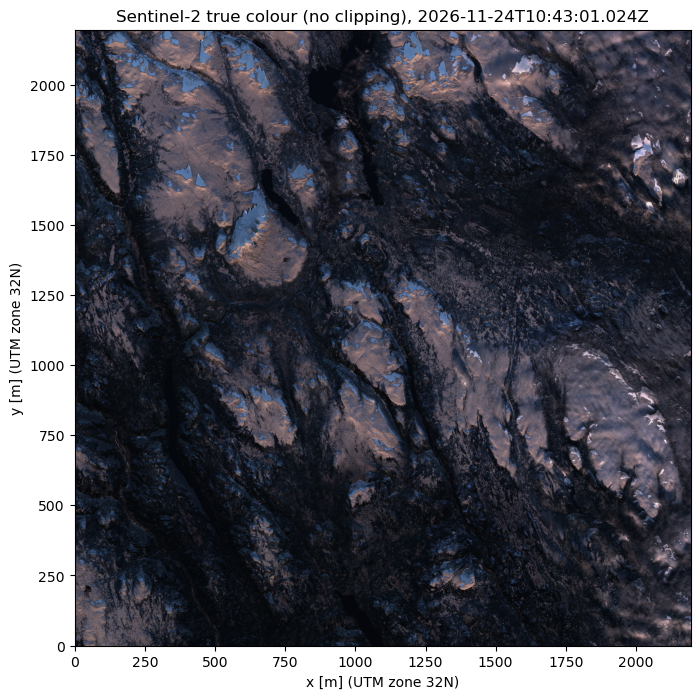

In [17]:
# Linear stretch using the full range of the data: min -> 0, max -> 1
vmin, vmax = rgb.min(), rgb.max()
rgb_full = (rgb - vmin) / (vmax - vmin)

show_rgb(rgb_full, f"Sentinel-2 true colour (no clipping), {ds.attrs['time_coverage_start']}")

### 6.5 Plot with the histogram clipped between 2 and 98 %

A common remedy is a **percentile clip**. We find the reflectance values below which 2 % and 98 % of the pixels fall, and use these as the new minimum and maximum. Values outside this range are clipped to 0 or 1 with `np.clip`, and the remaining values are stretched linearly over the full 0-1 range. The same limits are used for all three bands to preserve the colour balance. Bright clouds and snow will saturate, but the contrast of the rest of the scene improves considerably.

2 %: 0.146, 98 %: 0.979


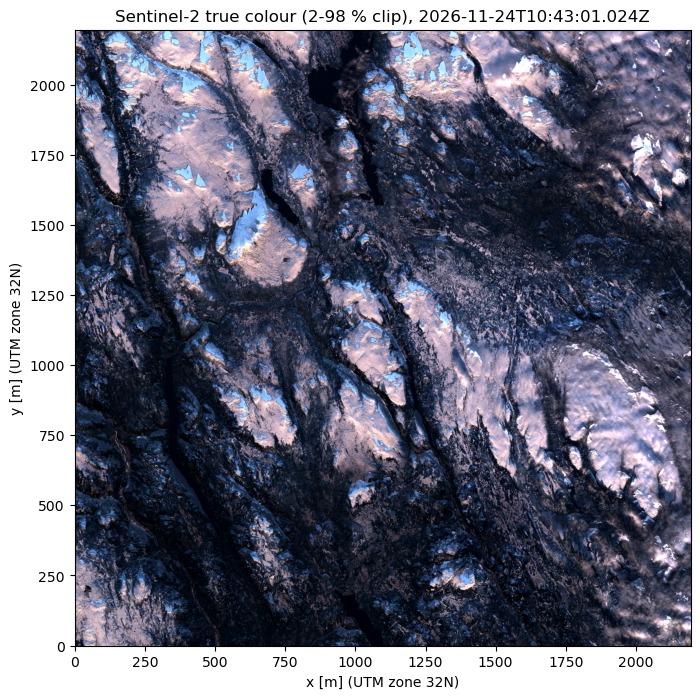

In [18]:
# Reflectance values at the 2nd and 98th percentiles
p_low, p_high = np.percentile(rgb, (2, 98))
print(f"2 %: {p_low:.3f}, 98 %: {p_high:.3f}")

# Clip to this range and stretch linearly to 0-1
rgb_clipped = np.clip((rgb - p_low) / (p_high - p_low), 0, 1)

show_rgb(rgb_clipped, f"Sentinel-2 true colour (2-98 % clip), {ds.attrs['time_coverage_start']}")